In [ ]:
# 1. Install Dependencies
!pip install -q unsloth
!pip install -q --no-deps trl peft accelerate bitsandbytes
!pip install -q huggingface_hub scikit-learn matplotlib

import os, json, glob, re, math, random
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from unsloth import FastVisionModel, UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig, GRPOTrainer, GRPOConfig
from datasets import Dataset
from huggingface_hub import notebook_login

print("Please log in to Hugging Face with a WRITE token:")
notebook_login()

DATASET_DIR = "/kaggle/input/datasets/franktapira/arxiv-training-data-zip"

# 80% Train, 10% Val, 10% Test
image_paths = sorted(glob.glob(f"{DATASET_DIR}/images/*.png"))
valid_pairs = []

for img_path in image_paths:
    chart_id = os.path.basename(img_path).replace(".png", "")
    json_path = f"{DATASET_DIR}/labels/{chart_id}.json"
    if os.path.exists(json_path) and os.path.getsize(json_path) > 0:
        valid_pairs.append((img_path, json_path))

random.seed(42)
random.shuffle(valid_pairs)
train_pairs, temp_pairs = train_test_split(valid_pairs, test_size=0.2, random_state=42)
val_pairs, test_pairs = train_test_split(temp_pairs, test_size=0.5, random_state=42)

print(f"✅ Data Split: {len(train_pairs)} Train | {len(val_pairs)} Val | {len(test_pairs)} Test")

In [2]:
MOVE_EXPERTS = ["CLAHE", "Bilateral_NoiseReduction", "Canny_EdgeDetection", "Otsu_Thresholding", "Morphology_Clean", "None"]

def format_sft_data(pair):
    img_path, json_path = pair
    with open(json_path, "r") as f:
        target_json_data = json.load(f)
    
    expert_tag = target_json_data.get("visual_expert_prompt", "None")
    if "Contrast" in expert_tag: chosen_expert = "CLAHE"
    elif "Noise" in expert_tag: chosen_expert = "Bilateral_NoiseReduction"
    elif "Edge" in expert_tag: chosen_expert = "Canny_EdgeDetection"
    elif "Threshold" in expert_tag: chosen_expert = "Otsu_Thresholding"
    elif "Morphology" in expert_tag: chosen_expert = "Morphology_Clean"
    else: chosen_expert = "None"
    
    target_json_str = json.dumps(target_json_data.get("chart_data", target_json_data))
    # Prompt explicitly teaches the model to act as a noisy sensor
    system_prompt = f"<thought>Analyze visual degradation. Simulate physical sensor noise.</thought>\n<expert>{chosen_expert}</expert>\n<json>{target_json_str}</json>"
    
    return {
        "messages": [
            {"role": "user", "content": [
                {"type": "image", "image": img_path},
                {"type": "text", "text": f"<image>\nAnalyze this chart. Select the best visual expert from: {MOVE_EXPERTS}. Output the data with continuous noise."}
            ]},
            {"role": "assistant", "content": [
                {"type": "text", "text": system_prompt}
            ]}
        ]
    }

train_dataset = Dataset.from_list([format_sft_data(p) for p in train_pairs])
val_dataset = Dataset.from_list([format_sft_data(p) for p in val_pairs])

model_name = "unsloth/Qwen2-VL-2B-Instruct-bnb-4bit"
model, processor = FastVisionModel.from_pretrained(model_name, load_in_4bit=True, use_gradient_checkpointing="unsloth")

model = FastVisionModel.get_peft_model(
    model, finetune_vision_layers=True, finetune_language_layers=True,
    finetune_attention_modules=True, finetune_mlp_modules=True,
    r=32, lora_alpha=32, lora_dropout=0.05, bias="none", random_state=3407,
)

sft_args = SFTConfig(
    output_dir="/kaggle/working/sft_warmup_model",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=1, 
    learning_rate=2e-4,
    logging_steps=5,
    eval_strategy="steps", 
    eval_steps=20, 
    optim="adamw_8bit",
    max_length=2048,
    dataset_kwargs={"skip_prepare_dataset": True}, 
)

trainer = SFTTrainer(
    model=model,
    tokenizer=processor.tokenizer,
    data_collator=UnslothVisionDataCollator(model, processor), 
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    args=sft_args,
)

print("🚀 Starting SFT Warmup (Teaching MoVE Routing)...")
trainer.train()
trainer.save_model("/kaggle/working/sft_warmup_model")
processor.save_pretrained("/kaggle/working/sft_warmup_model")

==((====))==  Unsloth 2026.11.3: Fast Qwen2_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen2VLDecoderLayer).
Unsloth: Model does not have a default image size - using 512
🚀 Starting SFT Warmup (Teaching MoVE Routing)...


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 779 | Num Epochs = 1 | Total steps = 195
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 4 x 1) = 4
 "-____-"     Trainable parameters = 57,901,056 of 2,266,886,656 (2.55% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
20,0.443404,0.337222
40,0.207915,0.225316
60,0.226410,0.204795
80,0.210010,0.192785
100,0.166215,0.185763
120,0.149653,0.181288
140,0.197356,0.178416
160,0.178857,0.174125
180,0.175735,0.172404
195,0.176200,0.171519


Unsloth: Not an error, but `num_items_in_batch` could not be counted for Qwen2VLForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/sft_warmup_model/checkpoint-195/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/sft_warmup_model/tokenizer_config.json.


['/kaggle/working/sft_warmup_model/processor_config.json']

In [3]:
import os, json, glob, re, math
import torch
from PIL import Image
from unsloth import FastVisionModel
from trl import GRPOTrainer, GRPOConfig
from datasets import Dataset

# 1. Load SFT Model
print("Loading SFT Model...")
model, processor = FastVisionModel.from_pretrained(
    "/kaggle/working/sft_warmup_model", 
    load_in_4bit=True, 
    use_gradient_checkpointing="unsloth"
)
FastVisionModel.for_training(model)

MOVE_EXPERTS = ["CLAHE", "Bilateral_NoiseReduction", "Canny_EdgeDetection", "Otsu_Thresholding", "Morphology_Clean", "None"]

def format_rl_data(pair):
    img_path, json_path = pair
    with open(json_path, "r") as f:
        gt_data = json.load(f)
        
    expert_tag = gt_data.get("visual_expert_prompt", "None")
    if "Contrast" in expert_tag: true_expert = "CLAHE"
    elif "Noise" in expert_tag: true_expert = "Bilateral_NoiseReduction"
    elif "Edge" in expert_tag: true_expert = "Canny_EdgeDetection"
    elif "Threshold" in expert_tag: true_expert = "Otsu_Thresholding"
    elif "Morphology" in expert_tag: true_expert = "Morphology_Clean"
    else: true_expert = "None"
    
    gt_json = json.dumps(gt_data.get("chart_data", gt_data))
    
    prompt_messages = [
        {"role": "user", "content": [
            {"type": "image"},
            {"type": "text", "text": f"Extract data. Select best expert from {MOVE_EXPERTS}. Act as a physical sensor with Gaussian measurement error. Be precise with floats."}
        ]}
    ]
    return {"prompt": prompt_messages, "image": Image.open(img_path).convert("RGB"), "ground_truth": gt_json, "true_expert": true_expert}

# Prepare RL Data
rl_train_dataset = Dataset.from_list([format_rl_data(p) for p in train_pairs[:100]])
rl_val_dataset = Dataset.from_list([format_rl_data(p) for p in val_pairs[:20]])
print(f"✅ RL Data Ready: {len(rl_train_dataset)} Train | {len(rl_val_dataset)} Val")

# 2. The Reward Function (MoVE + MAE + Variance)
def move_variance_reward_func(prompts, completions, ground_truth, true_expert, **kwargs):
    rewards = []
    
    # Process in groups of 2 (num_generations=2)
    for i in range(0, len(completions), 2):
        group_completions = completions[i:i+2]
        group_gt = ground_truth[i]
        group_expert = true_expert[i]
        
        group_rewards = []
        extracted_y_values = []
        
        for comp in group_completions:
            score = 0.0
            
            # 1. Truncation Penalty
            if len(comp) >= 750: score -= 2.0
                
            # 2. MoVE Routing Reward (R_route)
            if "<thought>" in comp: score += 1.0
            expert_match = re.search(r'<expert>(.*?)</expert>', comp, re.DOTALL)
            if expert_match and expert_match.group(1).strip() == group_expert:
                score += 3.0 # Bonus for correct latent routing
                
            # 3. Continuous MAE Reward (R_MAE)
            try:
                json_match = re.search(r'<json>(.*?)</json>', comp, re.DOTALL)
                if json_match:
                    pred_json = json.loads(json_match.group(1).strip())
                    true_json = json.loads(group_gt)
                    
                    # Extract Y values for Variance Calculation
                    if "series" in pred_json and len(pred_json["series"]) > 0:
                        data_points = pred_json["series"][0].get("data", [])
                        if len(data_points) > 0 and "y" in data_points[0]:
                            extracted_y_values.append(float(data_points[0]["y"]))
                            
                    def extract_nums(obj):
                        nums = []
                        if isinstance(obj, dict):
                            for v in obj.values(): nums.extend(extract_nums(v))
                        elif isinstance(obj, list):
                            for item in obj: nums.extend(extract_nums(item))
                        elif isinstance(obj, (int, float)): nums.append(obj)
                        return nums
                    
                    pred_nums = extract_nums(pred_json)
                    true_nums = extract_nums(true_json)
                    
                    if len(pred_nums) == len(true_nums) and len(pred_nums) > 0:
                        mae = sum(abs(p - t) for p, t in zip(pred_nums, true_nums)) / len(pred_nums)
                        score += 10.0 * math.exp(-mae * 10) 
            except Exception: pass
            group_rewards.append(score)
            
        # 4. Latent Noise Embedding (R_variance)
        # If the model outputs the exact same number (0.8 and 0.8), variance is 0.
        if len(extracted_y_values) > 1:
            mean_y = sum(extracted_y_values) / len(extracted_y_values)
            variance = sum((y - mean_y) ** 2 for y in extracted_y_values) / len(extracted_y_values)
            variance_reward = min(2.0, variance * 100) # Scale variance up for reward
            group_rewards = [r + variance_reward for r in group_rewards]
            
        rewards.extend(group_rewards)
        
    return rewards

# 3. GRPO Configuration
training_args = GRPOConfig(
    output_dir="/kaggle/working/qwen2vl_rl_final",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    learning_rate=5e-6,
    num_train_epochs=1,
    logging_steps=2,
    eval_strategy="steps",
    eval_steps=10,
    max_completion_length=1024, 
    num_generations=2,          
    optim="adamw_8bit",
    save_strategy="epoch",
)

trainer = GRPOTrainer(
    model=model,
    processing_class=processor,
    reward_funcs=move_variance_reward_func,
    args=training_args,
    train_dataset=rl_train_dataset,
    eval_dataset=rl_val_dataset,
)

print("🚀 Starting RL Training (Optimizing MoVE, MAE, and Variance)...")
trainer.train()

# Save Final Model
model.save_pretrained("/kaggle/working/final_rl_latent_moe")
processor.save_pretrained("/kaggle/working/final_rl_latent_moe")
print("✅ RL Training Complete!")

Loading SFT Model...
==((====))==  Unsloth 2026.11.3: Fast Qwen2_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

✅ RL Data Ready: 100 Train | 20 Val
Unsloth: GRPO now defaults to TRL's loss_type = 'dapo' with beta = 0.0. Set loss_type = 'bnpo', beta = 0.001 for Unsloth's previous default.
🚀 Starting RL Training (Optimizing MoVE, MAE, and Variance)...


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 100 | Num Epochs = 1 | Total steps = 50
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 4 x 1) = 4
 "-____-"     Trainable parameters = 57,901,056 of 2,266,886,656 (2.55% trained)
Passing `generation_config` together with generation-related arguments=({'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. 

Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss,Num Tokens,Completions/mean Length,Completions/min Length,Completions/max Length,Completions/clipped Ratio,Completions/mean Terminated Length,Completions/min Terminated Length,Completions/max Terminated Length,Rewards/move Variance Reward Func/mean,Rewards/move Variance Reward Func/std,Reward,Reward Std,Frac Reward Zero Std,Completion Length,Kl,Clip Ratio/low Mean,Clip Ratio/low Min,Clip Ratio/high Mean,Clip Ratio/high Max,Clip Ratio/region Mean
10,0.039401,0.023374,79603.000000,447.625000,316.700000,632.400000,0.025000,432.425000,316.700000,578.800000,2.779123,0.569703,2.779123,0.569703,0.700000,447.625000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
20,-0.004148,0.025179,156487.000000,463.475000,351.100000,617.000000,0.000000,463.475000,351.100000,617.000000,3.167761,0.888169,3.167761,0.888169,0.800000,463.475000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
30,0.000694,0.019490,236989.000000,455.500000,300.400000,629.100000,0.000000,455.500000,300.400000,629.100000,2.998734,1.007674,2.998734,1.007674,0.800000,455.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
40,0.077258,0.040577,313147.000000,434.325000,305.600000,596.400000,0.000000,434.325000,305.600000,596.400000,3.107498,0.518457,3.107498,0.518457,0.750000,434.325000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50,0.070765,0.052729,388492.000000,428.550000,274.300000,612.600000,0.000000,428.550000,274.300000,612.600000,3.024740,0.908554,3.024740,0.908554,0.700000,428.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

✅ RL Training Complete!


🔬 Running Final Verification with Latent Noise...

--- Test Image 1 ---


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


🧠 MoVE Latent Routing: Model selected -> [None]


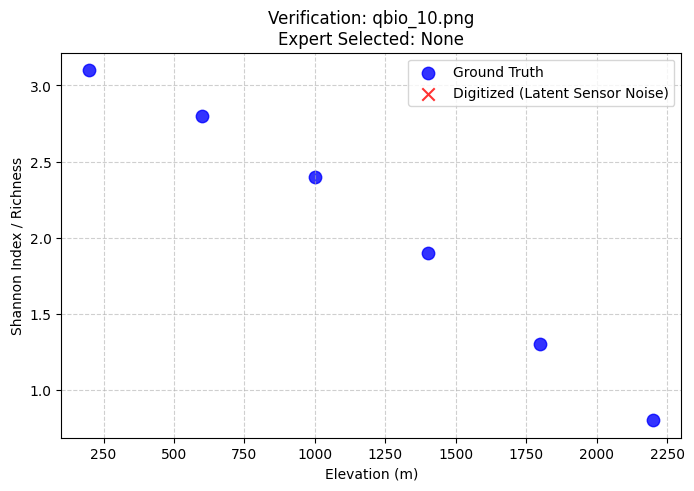


--- Test Image 2 ---


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


🧠 MoVE Latent Routing: Model selected -> [None]


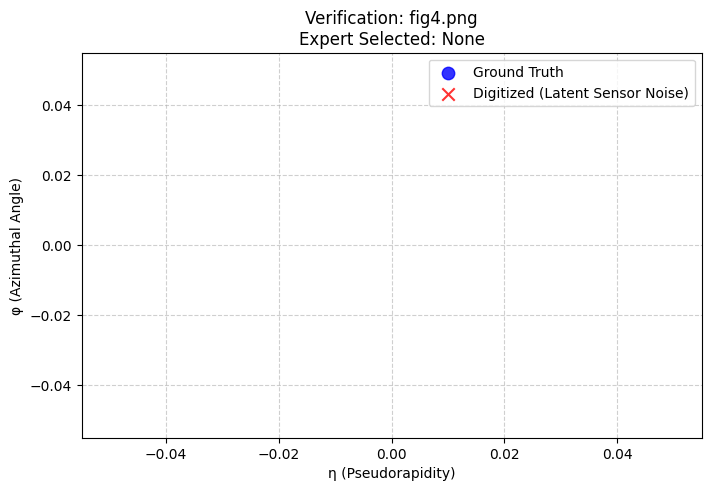


--- Test Image 3 ---


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


🧠 MoVE Latent Routing: Model selected -> [None]


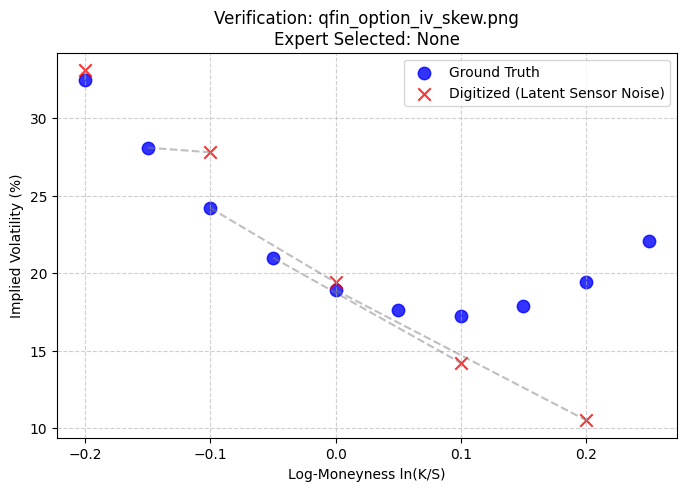

In [4]:
def verify_and_plot(pair, model, processor):
    img_path, json_path = pair
    with open(json_path, "r") as f:
        gt_data_raw = json.load(f)
        gt_data = gt_data_raw.get("chart_data", gt_data_raw)
        
    image = Image.open(img_path).convert("RGB")
    prompt = f"<image>\nExtract data. Select best expert from {MOVE_EXPERTS}. Act as a physical sensor with Gaussian measurement error."
    
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    inputs = processor(image, processor.apply_chat_template(messages, add_generation_prompt=True), return_tensors="pt").to("cuda")
    
    # --- NATIVE LATENT NOISE VIA TEMPERATURE ---
    # We set temperature=0.7 and do_sample=True. 
    # Because of the Variance Reward during RL, the model's logits are flattened,
    # so this sampling will natively generate the Gaussian noise.
    outputs = model.generate(
        **inputs, 
        max_new_tokens=1024, 
        temperature=0.7, 
        do_sample=True, 
        top_p=0.9
    )
    result = processor.decode(outputs[0], skip_special_tokens=True)
    
    raw_output = result.split("assistant\n")[-1]
    expert_match = re.search(r'<expert>(.*?)</expert>', raw_output, re.DOTALL)
    json_match = re.search(r'<json>(.*?)</json>', raw_output, re.DOTALL)
    
    selected_expert = expert_match.group(1).strip() if expert_match else "Unknown"
    print(f"🧠 MoVE Latent Routing: Model selected -> [{selected_expert}]")
    
    if not json_match: return
        
    try:
        pred_data = json.loads(json_match.group(1).strip())
    except Exception as e:
        print(f"❌ Invalid JSON: {e}")
        return

    gt_series = gt_data.get("series", [])
    pred_series = pred_data.get("series", [])
    if not gt_series or not pred_series: return

    gt_points = gt_series[0].get("data", [])
    pred_points = pred_series[0].get("data", [])
    
    gt_x = [p.get("x") for p in gt_points if "x" in p]
    gt_y = [p.get("y") for p in gt_points if "y" in p]
    pred_x = [p.get("x") for p in pred_points if "x" in p]
    pred_y = [p.get("y") for p in pred_points if "y" in p]

    plt.figure(figsize=(8, 5))
    plt.scatter(gt_x, gt_y, color='blue', label='Ground Truth', marker='o', s=80, alpha=0.8)
    plt.scatter(pred_x, pred_y, color='red', label='Digitized (Latent Sensor Noise)', marker='x', s=80, alpha=0.8)
    
    for i in range(min(len(gt_x), len(pred_x))):
        plt.plot([gt_x[i], pred_x[i]], [gt_y[i], pred_y[i]], color='gray', linestyle='--', alpha=0.5)

    plt.title(f"Verification: {os.path.basename(img_path)}\nExpert Selected: {selected_expert}")
    plt.xlabel(gt_data.get("axes", {}).get("x", {}).get("label", "X"))
    plt.ylabel(gt_data.get("axes", {}).get("y", {}).get("label", "Y"))
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

print("🔬 Running Final Verification with Latent Noise...")
FastVisionModel.for_inference(model)

for i in range(min(3, len(test_pairs))):
    print(f"\n--- Test Image {i+1} ---")
    verify_and_plot(test_pairs[i], model, processor)

Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


🚀 Starting Full Evaluation on 98 Test Images...



Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

Processed 20/98 images...


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

Processed 40/98 images...


... (2 outputs left out)

Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

Processed 80/98 images...


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_


📊 FINAL TEST SET EVALUATION REPORT
Total Images Tested:      98
Routing Accuracy:         100.00% (98/98)
JSON Validity Rate:       89.80% (88/98)
Data Extraction Rate:     89.80% (88/98)
Average MAE (Precision):  59174242424242457541347377152.0000

📈 Visualizing 3 Random Successful Plots...


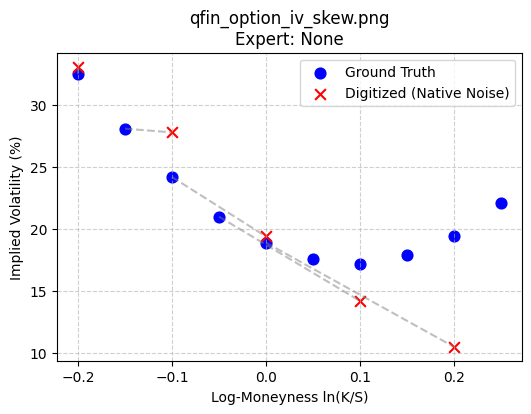

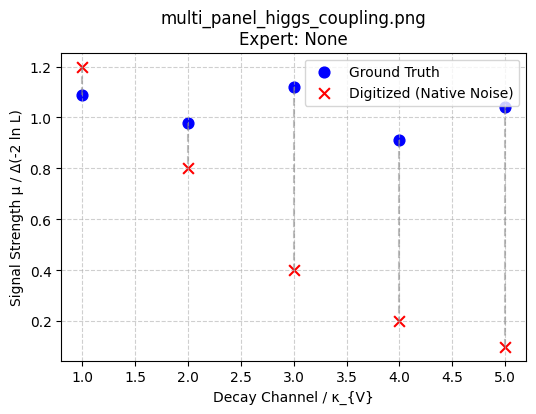

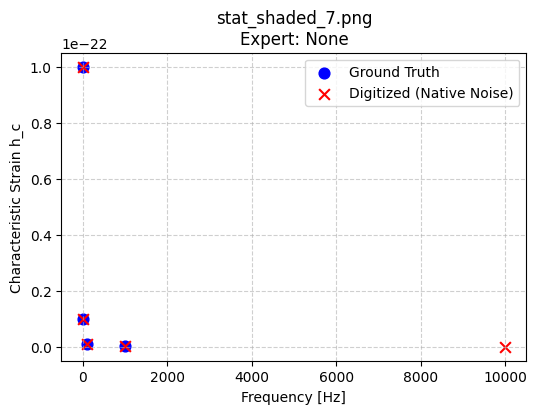

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import random

def extract_nums(obj):
    """Recursively extract all floats/integers from a JSON object."""
    nums = []
    if isinstance(obj, dict):
        for v in obj.values(): nums.extend(extract_nums(v))
    elif isinstance(obj, list):
        for item in obj: nums.extend(extract_nums(item))
    elif isinstance(obj, (int, float)): nums.append(float(obj))
    return nums

def evaluate_full_test_set(test_pairs, model, processor, num_visual_plots=3):
    print(f"🚀 Starting Full Evaluation on {len(test_pairs)} Test Images...\n")
    
    # Metrics
    valid_json_count = 0
    correct_routing_count = 0
    total_mae = 0.0
    mae_count = 0
    extraction_success_count = 0
    
    # Store successful plots for visual aid
    successful_plots = []
    
    for idx, pair in enumerate(test_pairs):
        img_path, json_path = pair
        with open(json_path, "r") as f:
            gt_data_raw = json.load(f)
            gt_data = gt_data_raw.get("chart_data", gt_data_raw)
            
        # Get true expert
        expert_tag = gt_data_raw.get("visual_expert_prompt", "None")
        if "Contrast" in expert_tag: true_expert = "CLAHE"
        elif "Noise" in expert_tag: true_expert = "Bilateral_NoiseReduction"
        elif "Edge" in expert_tag: true_expert = "Canny_EdgeDetection"
        elif "Threshold" in expert_tag: true_expert = "Otsu_Thresholding"
        elif "Morphology" in expert_tag: true_expert = "Morphology_Clean"
        else: true_expert = "None"

        # Run Inference
        image = Image.open(img_path).convert("RGB")
        prompt = f"<image>\nExtract data. Select best expert from {MOVE_EXPERTS}. Act as a physical sensor with Gaussian measurement error."
        messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
        inputs = processor(image, processor.apply_chat_template(messages, add_generation_prompt=True), return_tensors="pt").to("cuda")
        
        outputs = model.generate(**inputs, max_new_tokens=1024, temperature=0.7, do_sample=True)
        result = processor.decode(outputs[0], skip_special_tokens=True)
        raw_output = result.split("assistant\n")[-1]
        
        # 1. Routing Accuracy
        expert_match = re.search(r'<expert>(.*?)</expert>', raw_output, re.DOTALL)
        pred_expert = expert_match.group(1).strip() if expert_match else "Unknown"
        if pred_expert == true_expert:
            correct_routing_count += 1
            
        # 2. JSON Validity & MAE
        json_match = re.search(r'<json>(.*?)</json>', raw_output, re.DOTALL)
        if json_match:
            try:
                pred_data = json.loads(json_match.group(1).strip())
                valid_json_count += 1
                
                # Extract and compare numbers
                true_nums = extract_nums(gt_data)
                pred_nums = extract_nums(pred_data)
                
                if len(pred_nums) > 0 and len(true_nums) > 0:
                    extraction_success_count += 1
                    # Calculate MAE (using the first N matching elements to avoid length mismatch)
                    min_len = min(len(true_nums), len(pred_nums))
                    mae = sum(abs(p - t) for p, t in zip(pred_nums[:min_len], true_nums[:min_len])) / min_len
                    total_mae += mae
                    mae_count += 1
                
                # Save for plotting if it has valid series data
                if len(successful_plots) < num_visual_plots:
                    gt_series = gt_data.get("series", [])
                    pred_series = pred_data.get("series", [])
                    if gt_series and pred_series:
                        gt_points = gt_series[0].get("data", [])
                        pred_points = pred_series[0].get("data", [])
                        if len(gt_points) > 0 and len(pred_points) > 0:
                            successful_plots.append((img_path, gt_data, pred_data, pred_expert))
                            
            except Exception:
                pass # Failed JSON parsing
                
        if (idx + 1) % 20 == 0:
            print(f"Processed {idx + 1}/{len(test_pairs)} images...")

    # ==========================================
    # FINAL REPORT
    # ==========================================
    print("\n" + "="*40)
    print("📊 FINAL TEST SET EVALUATION REPORT")
    print("="*40)
    print(f"Total Images Tested:      {len(test_pairs)}")
    print(f"Routing Accuracy:         {(correct_routing_count/len(test_pairs))*100:.2f}% ({correct_routing_count}/{len(test_pairs)})")
    print(f"JSON Validity Rate:       {(valid_json_count/len(test_pairs))*100:.2f}% ({valid_json_count}/{len(test_pairs)})")
    print(f"Data Extraction Rate:     {(extraction_success_count/len(test_pairs))*100:.2f}% ({extraction_success_count}/{len(test_pairs)})")
    
    if mae_count > 0:
        avg_mae = total_mae / mae_count
        print(f"Average MAE (Precision):  {avg_mae:.4f}")
    else:
        print("Average MAE (Precision):  N/A (No valid data extracted)")
    print("="*40 + "\n")

    # ==========================================
    # VISUALIZE SUCCESSFUL PLOTS
    # ==========================================
    print(f"📈 Visualizing {len(successful_plots)} Random Successful Plots...")
    for i, (img_path, gt_data, pred_data, pred_expert) in enumerate(successful_plots):
        gt_points = gt_data["series"][0].get("data", [])
        pred_points = pred_data["series"][0].get("data", [])
        
        gt_x = [p.get("x") for p in gt_points if "x" in p]
        gt_y = [p.get("y") for p in gt_points if "y" in p]
        pred_x = [p.get("x") for p in pred_points if "x" in p]
        pred_y = [p.get("y") for p in pred_points if "y" in p]

        plt.figure(figsize=(6, 4))
        plt.scatter(gt_x, gt_y, color='blue', label='Ground Truth', marker='o', s=60)
        plt.scatter(pred_x, pred_y, color='red', label='Digitized (Native Noise)', marker='x', s=60)
        
        for j in range(min(len(gt_x), len(pred_x))):
            plt.plot([gt_x[j], pred_x[j]], [gt_y[j], pred_y[j]], color='gray', linestyle='--', alpha=0.5)

        plt.title(f"{os.path.basename(img_path)}\nExpert: {pred_expert}")
        plt.xlabel(gt_data.get("axes", {}).get("x", {}).get("label", "X"))
        plt.ylabel(gt_data.get("axes", {}).get("y", {}).get("label", "Y"))
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.show()

# Ensure model is ready
FastVisionModel.for_inference(model)

# Run the full evaluation
evaluate_full_test_set(test_pairs, model, processor, num_visual_plots=3)

In [ ]:
def evaluate_full_test_set(test_pairs, model, processor, num_visual_plots=3):
    print(f"🚀 Starting Full Evaluation on {len(test_pairs)} Test Images...\n")
    
    valid_json_count = 0
    correct_routing_count = 0
    total_mae = 0.0
    mae_count = 0
    successful_plots = []
    
    for idx, pair in enumerate(test_pairs):
        img_path, json_path = pair
        with open(json_path, "r") as f:
            gt_data_raw = json.load(f)
            gt_data = gt_data_raw.get("chart_data", gt_data_raw)
            
        expert_tag = gt_data_raw.get("visual_expert_prompt", "None")
        if "Contrast" in expert_tag: true_expert = "CLAHE"
        elif "Noise" in expert_tag: true_expert = "Bilateral_NoiseReduction"
        elif "Edge" in expert_tag: true_expert = "Canny_EdgeDetection"
        elif "Threshold" in expert_tag: true_expert = "Otsu_Thresholding"
        elif "Morphology" in expert_tag: true_expert = "Morphology_Clean"
        else: true_expert = "None"

        image = Image.open(img_path).convert("RGB")
        prompt = f"<image>\nExtract data. Select best expert from {MOVE_EXPERTS}. Act as a physical sensor with Gaussian measurement error."
        messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
        inputs = processor(image, processor.apply_chat_template(messages, add_generation_prompt=True), return_tensors="pt").to("cuda")
        
        outputs = model.generate(**inputs, max_new_tokens=1024, temperature=0.7, do_sample=True)
        result = processor.decode(outputs[0], skip_special_tokens=True)
        raw_output = result.split("assistant\n")[-1]
        
        # 1. Routing Accuracy
        expert_match = re.search(r'<expert>(.*?)</expert>', raw_output, re.DOTALL)
        pred_expert = expert_match.group(1).strip() if expert_match else "Unknown"
        if pred_expert == true_expert:
            correct_routing_count += 1
            
        # 2. JSON Validity & MAE (Strict X,Y only)
        json_match = re.search(r'<json>(.*?)</json>', raw_output, re.DOTALL)
        if json_match:
            try:
                pred_data = json.loads(json_match.group(1).strip())
                valid_json_count += 1
                
                # Extract strictly X and Y arrays
                gt_series = gt_data.get("series", [])
                pred_series = pred_data.get("series", [])
                
                if gt_series and pred_series:
                    gt_points = gt_series[0].get("data", [])
                    pred_points = pred_series[0].get("data", [])
                    
                    gt_x = [p.get("x") for p in gt_points if "x" in p]
                    gt_y = [p.get("y") for p in gt_points if "y" in p]
                    pred_x = [p.get("x") for p in pred_points if "x" in p]
                    pred_y = [p.get("y") for p in pred_points if "y" in p]
                    
                    if len(gt_x) == len(pred_x) and len(gt_y) == len(pred_y) and len(gt_x) > 0:
                        mae_x = sum(abs(a - b) for a, b in zip(gt_x, pred_x)) / len(gt_x)
                        mae_y = sum(abs(a - b) for a, b in zip(gt_y, pred_y)) / len(gt_y)
                        total_mae += (mae_x + mae_y) / 2
                        mae_count += 1
                        
                        if len(successful_plots) < num_visual_plots:
                            successful_plots.append((img_path, gt_data, pred_data, pred_expert))
            except Exception:
                pass 
                
    # REPORT
    print("\n" + "="*40)
    print("📊 FINAL TEST SET EVALUATION REPORT")
    print("="*40)
    print(f"Total Images Tested:      {len(test_pairs)}")
    print(f"Routing Accuracy:         {(correct_routing_count/len(test_pairs))*100:.2f}%")
    print(f"JSON Validity Rate:       {(valid_json_count/len(test_pairs))*100:.2f}%")
    
    if mae_count > 0:
        print(f"Average Coordinate MAE:   {total_mae / mae_count:.4f}")
    else:
        print("Average Coordinate MAE:   N/A (Array lengths mismatched)")
    print("="*40 + "\n")

    # PLOTTING
    for i, (img_path, gt_data, pred_data, pred_expert) in enumerate(successful_plots):
        gt_points = gt_data["series"][0].get("data", [])
        pred_points = pred_data["series"][0].get("data", [])
        
        gt_x = [p.get("x") for p in gt_points if "x" in p]
        gt_y = [p.get("y") for p in gt_points if "y" in p]
        pred_x = [p.get("x") for p in pred_points if "x" in p]
        pred_y = [p.get("y") for p in pred_points if "y" in p]

        plt.figure(figsize=(6, 4))
        plt.scatter(gt_x, gt_y, color='blue', label='Ground Truth', marker='o', s=60)
        plt.scatter(pred_x, pred_y, color='red', label='Digitized', marker='x', s=60)
        
        for j in range(min(len(gt_x), len(pred_x))):
            plt.plot([gt_x[j], pred_x[j]], [gt_y[j], pred_y[j]], color='gray', linestyle='--', alpha=0.5)

        plt.title(f"{os.path.basename(img_path)} | Expert: {pred_expert}")
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.show()

FastVisionModel.for_inference(model)
evaluate_full_test_set(test_pairs, model, processor, num_visual_plots=3)

Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


🚀 Starting Full Evaluation on 98 Test Images...



Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_